# Домашнее задание по теме «Деревья решений: регрессия и классификация»

<!-- **Максимальная оценка за домашнюю работу – 10 баллов. Однако сумма баллов за все задания равна 12. Выбирай задания по вкусу или делай все с запасом!**  -->

В этом домашнем задании ты узнаешь, как деревья решений разбивают данные по признакам, выбирают оптимальные точки разбиения и последовательно строят структуру «ветвей» до готового прогноза.

В домашней работе две независимые части:
- деревья регрессии (датасет Wine Quality);
- деревья классификации (датасет Adult).

<!-- В каждой части тебя ждёт:    
* лёгкий разогрев с EDA + `sklearn`;  
* задания на свой (кастомный) класс дерева.-->

Ты научишься:  
- строить деревья;
- использовать критерии разбиения (Джини, энтропию);
- контролировать глубину дерева и предотвращать переобучение с помощью обрезки и регуляризации;
- анализировать важность признаков и оценивать качество модели на валидации.  

<!-- В конце добавлены 2 теоретических вопроса по 0.5 баллов каждый. -->



## Часть I. Деревья регрессии

Импортируем библиотеки и [загрузим датасет Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).

Датасет Wine Quality содержит данные о винах Португалии, собранных в районе Валенсии. В датасете два отдельных файла: около 1 600 записей для красного вина и почти 4 900 для белого. На каждый образец приходится 11 физических и химических характеристик (фиксированная кислотность, летучая кислотность, цитрат, остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и содержание алкоголя) и целевая метка `quality` — оценка дегустатора от 0 до 10 (на практике в диапазоне ~ 3–9).

Обычно Wine Quality используют для задач регрессии, чтобы предсказать точечную оценку. Или для бинарной классификации, например, чтобы определить «низкое» или «высокое» качество, где порог — это 6. Используем датасет для задачи регрессии и  предскажем переменную `quality`.



In [ ]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

Теперь загрузим датасет и проведём разведочный анализ данных (EDA) и препроцессинг.

In [ ]:
# 1. Ссылки на CSV
red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

# 2. Считываем в DataFrame, указывая разделитель ';'
df_red = pd.read_csv(red_url, sep=';')
df_white = pd.read_csv(white_url, sep=';')

# 3. Добавляем колонку с типом вина
df_red["type"] = "red"
df_white["type"] = "white"

# 4. Объединяем
df = pd.concat([df_red, df_white], ignore_index=True)

# 5. Проверка
print(df.shape)   # Сколько записей и признаков
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [ ]:
# Нет пропусков, один категориальный признак
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [ ]:
# Есть выбросы
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


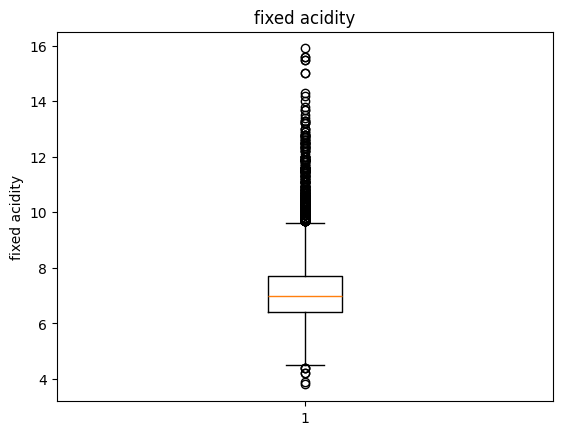

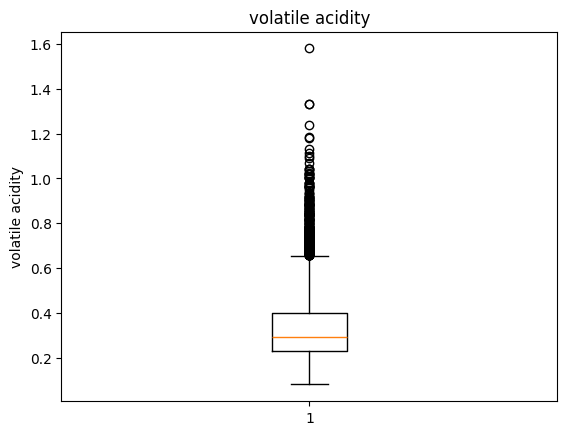

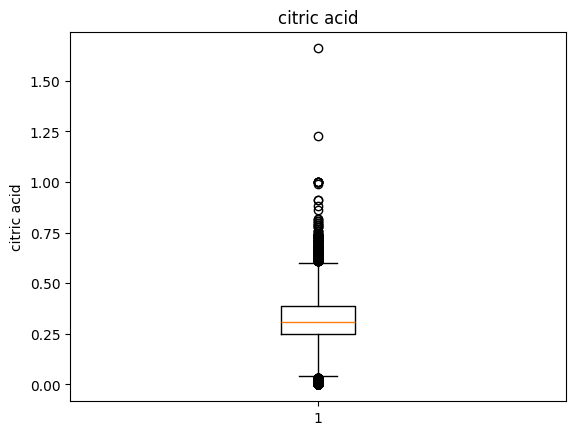

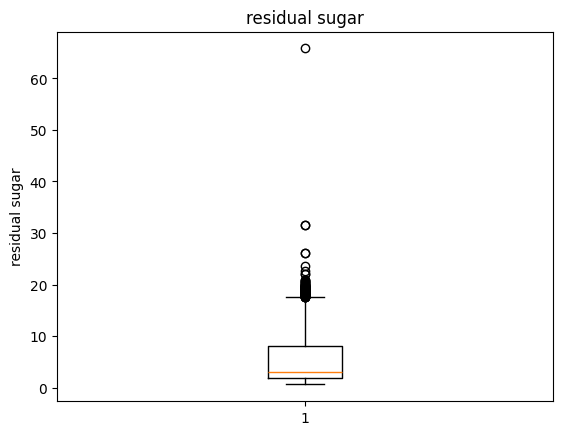

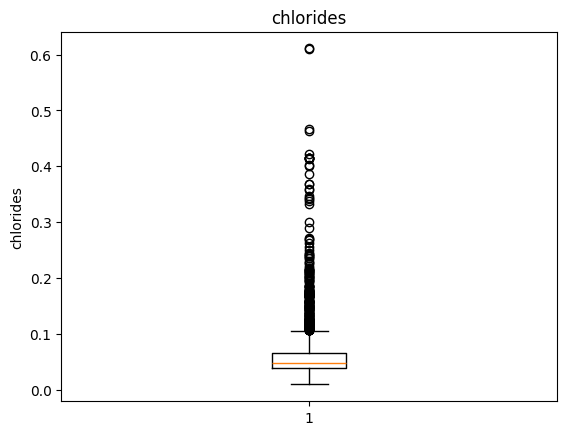

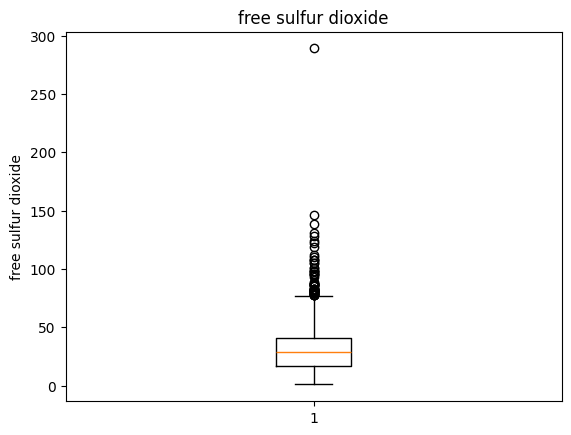

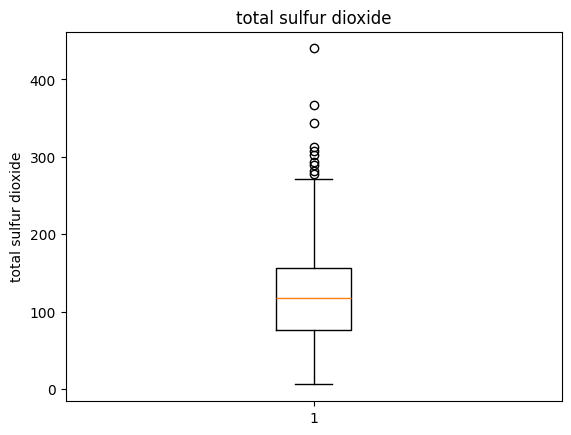

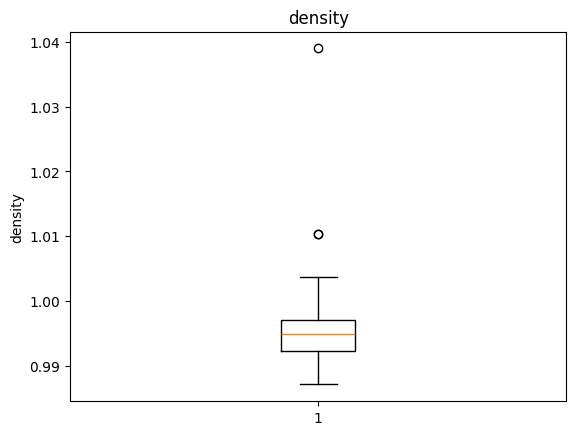

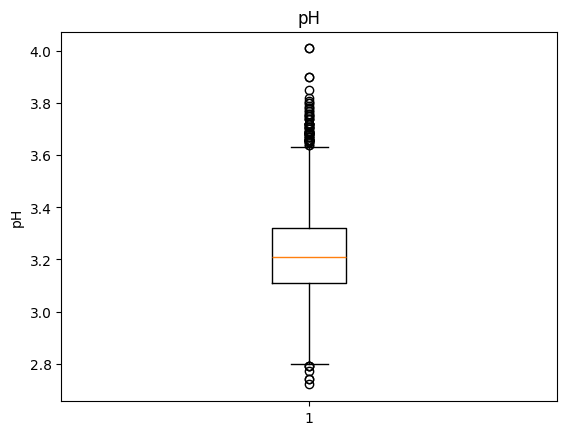

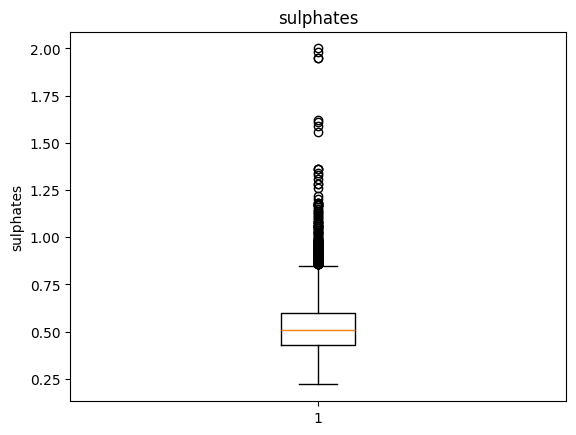

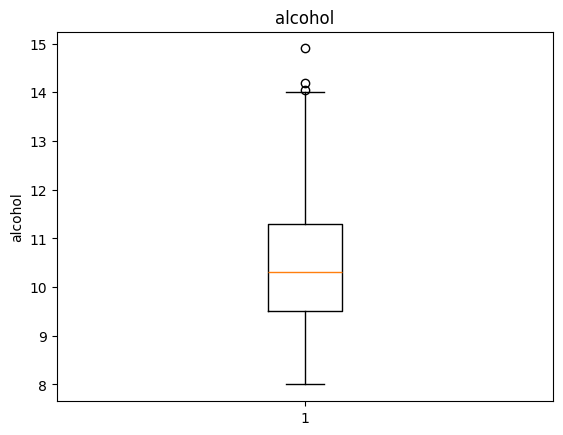

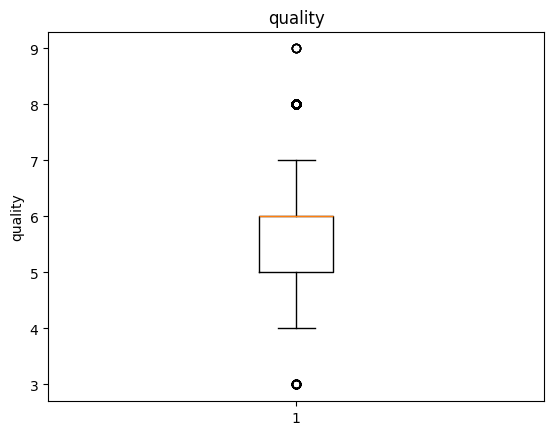

In [ ]:
# Много выбросов
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure()
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel(col)
    plt.show()

In [ ]:
Q1, Q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
IQR = Q3 - Q1
mask = (df[num_cols] < (Q1 - 1.5*IQR)) | (df[num_cols] > (Q3 + 1.5*IQR))

print("Количество выбросов в каждом столбце")
print(mask.sum().sort_values(ascending=False))

Количество выбросов в каждом столбце
citric acid             509
volatile acidity        377
fixed acidity           357
chlorides               286
quality                 228
sulphates               191
residual sugar          118
pH                       73
free sulfur dioxide      62
total sulfur dioxide     10
density                   3
alcohol                   3
dtype: int64


В этой задаче мы имеем дело как с редкими значениями, так и с явными ошибками. Например, значение `residual sugar > 60` выбивается из других наблюдений и, скорее всего, ошибочно, так как такое количество сахара в готовом вине маловероятно.

Выберем тактику «подавления» экстремальных значений до 99% перцентилей. Это нужно, чтобы дерево не переобучалось на явно нереалистичных наблюдениях и не теряло обобщающую способность.

In [ ]:
# Заменим экстремальные значения на 99% перцентильные значения
# Выбираем только числовые столбцы
num_cols = df.select_dtypes(include='number').columns

# Считаем 1-й и 99-й перцентиль для каждого из них
lower = df[num_cols].quantile(0.01)
upper = df[num_cols].quantile(0.99)

# «Клипируем» значения вне этого диапазона
df[num_cols] = df[num_cols].clip(lower=lower, upper=upper, axis=1)

# Проверяем результат
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.207611,1.243883,5.10000,6.40000,7.00000,7.70000,12.00000
volatile acidity,6497.0,0.338606,0.159793,0.12000,0.23000,0.29000,0.40000,0.88000
citric acid,6497.0,0.317928,0.142346,0.00000,0.25000,0.31000,0.39000,0.74000
residual sugar,6497.0,5.417824,4.638290,0.90000,1.80000,3.00000,8.10000,18.20000
chlorides,6497.0,0.055023,0.027264,0.02100,0.03800,0.04700,0.06500,0.18616
free sulfur dioxide,6497.0,30.350623,16.887096,4.00000,17.00000,29.00000,41.00000,77.00000
total sulfur dioxide,6497.0,115.560028,55.901335,11.00000,77.00000,118.00000,156.00000,238.00000
density,6497.0,0.994683,0.002905,0.98892,0.99234,0.99489,0.99699,1.00060
pH,6497.0,3.218041,0.157237,2.89000,3.11000,3.21000,3.32000,3.64000
sulphates,6497.0,0.529304,0.137758,0.30000,0.43000,0.51000,0.60000,0.99000


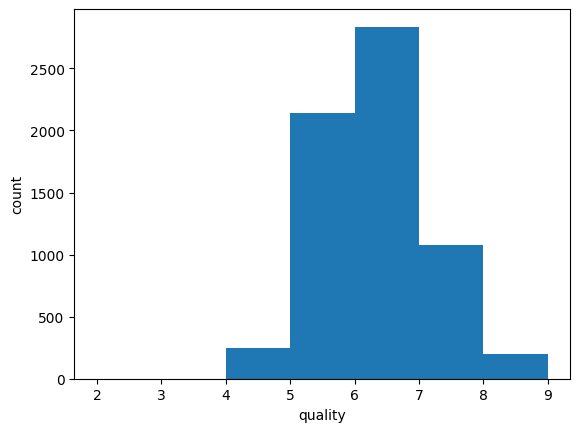

In [ ]:
# Распределение целевой
# Минимум — 4, максимум — 8
plt.hist(df["quality"], bins=range(2,10))
plt.xlabel("quality")
plt.ylabel("count")
plt.show()

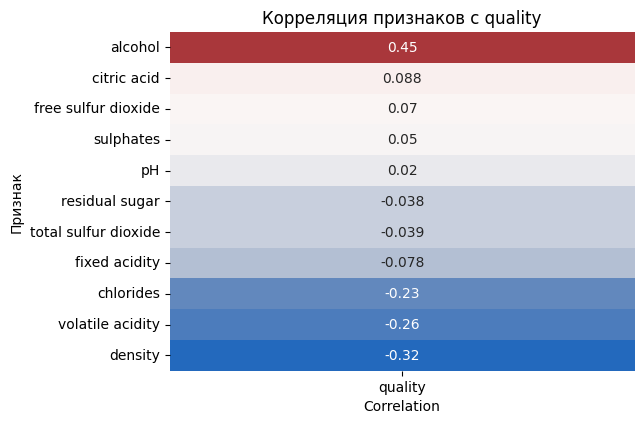

In [ ]:
# 1. Считаем матрицу корреляций
corr = df.corr(numeric_only=True)

# 2. Берём только столбец quality, убираем строку quality и сортируем
corr_q = corr["quality"].drop("quality").sort_values(ascending=False)

# 3. Рисуем теплокарту
plt.figure(figsize=(6, len(corr_q) * 0.4))
sns.heatmap(corr_q.to_frame(), annot=True, cmap="vlag", cbar=False)
plt.title("Корреляция признаков с quality")
plt.ylabel("Признак")
plt.xlabel("Correlation")
plt.show()

In [ ]:
# Работаем с категориальной фичей
df = pd.get_dummies(df, columns=["type"], drop_first=True)  # Появится столбец type_white
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_white
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,False
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,False
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,False
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,False
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,False


In [ ]:
X = df.drop(["quality"], axis=1)
y = df["quality"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

### Задача 1. `sklearn`: неограниченное дерево [1 балл]  

Работаем с датасетом Wine Quality. Будем предсказывать оценку качества вина.

  




#### Задача 1.1 [0,5 балла]

- Обучи неограниченное дерево `DecisionTreeRegressor(random_state=42)` и выведи $R^2$ на тесте.

- Выведи глубину дерева и число листьев.

In [ ]:
# Напиши код здесь
regressor = DecisionTreeRegressor(random_state=42)
regressor.fit(X_train, y_train)

y_pred = regressor.predict(X_test)
r2 = r2_score(y_test, y_pred)

print(f"R^2: {r2:.4f}")
print(f"Глубина дерева: {regressor.get_depth()}")
print(f"Число листьев: {regressor.get_n_leaves()}")

R^2: 0.0336
Глубина дерева: 23
Число листьев: 1260


#### Задача 1.2 [0,5 балла]

Отрисуй первые три уровня полученного дерева с помощью `plot_tree` (параметр `max_depth = 2`).

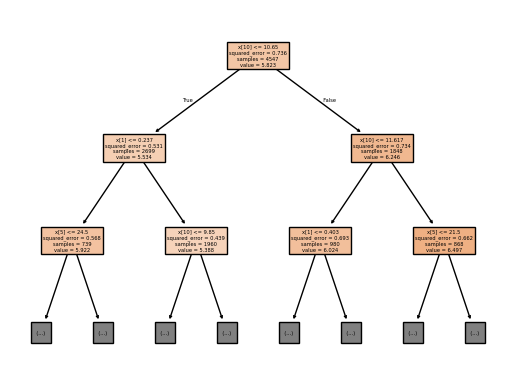

In [ ]:
# Напиши код здесь
tree.plot_tree(regressor, max_depth=2, filled=True)
plt.show()

### Задача 2. `sklearn`: ограниченное дерево [2 балла]  

Неограниченное дерево показало плохие результаты на тестовых данных. Нужно его ограничить с помощью pre-pruning-методов, регулируя гиперпараметры.







#### Задача 2.1 [0,5 балла]

- Напиши цикл, который будет проходить по различным значениям `max_depth` (от 1 до 23).

- Для каждого значения глубины обучи `DecisionTreeRegressor` с заданной глубиной на обучающих данных.

- Вычисли $R^2$ только на тестовой выборке.

- Нарисуй график зависимости тестового $R^2$ от глубины дерева.

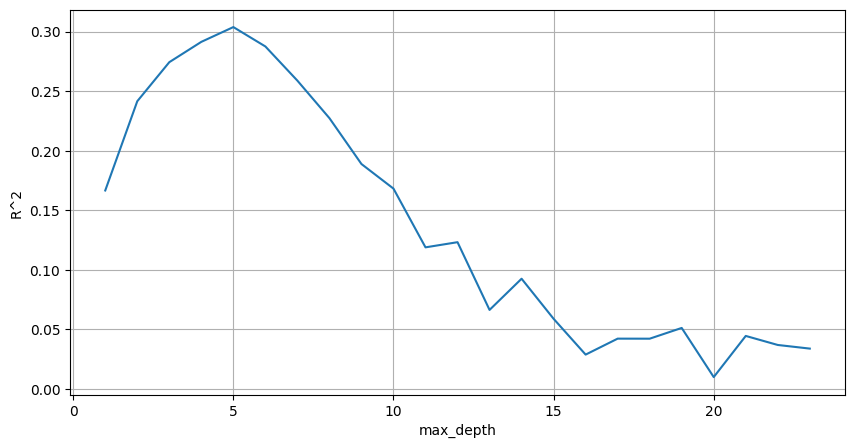

In [ ]:
# Напиши код здесь
depths = range(1, 24)
test_r2_depth = []

for d in depths:
    model = DecisionTreeRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_r2_depth.append(r2_score(y_test, y_pred))

plt.figure(figsize=(10, 5))
plt.plot(depths, test_r2_depth)
plt.xlabel('max_depth')
plt.ylabel('R^2')
plt.grid(True)
plt.show()

#### Задача 2.2 [0,5 балла]  

- Напиши аналогичный цикл для гиперпараметра `min_samples_split`. Массив значений, которые надо проверить: `splits = [10, 20, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000, 1500, 2000]`.

- Нарисуй аналогичный график.

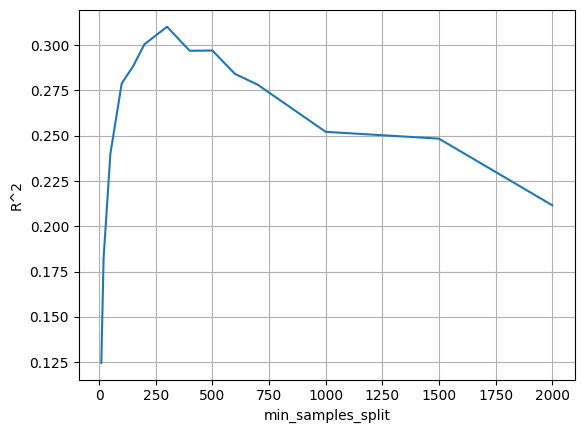

In [ ]:
# Напиши код здесь
splits = [10, 20, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000, 1500, 2000]
test_r2_split = []

for s in splits:
    model = DecisionTreeRegressor(min_samples_split=s, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_r2_split.append(r2_score(y_test, y_pred))

plt.plot(splits, test_r2_split)
plt.xlabel('min_samples_split')
plt.ylabel('R^2')
plt.grid(True)
plt.show()

#### Задача 2.3 [0,5 балла]

**Вопрос.** Как можно объяснить два нарисованных графика?

Твой ответ здесь:

График зависимости от max_depth показывает переобучения: при малых глубинах модель недообучена, затем качество растет, достигает пика, а затем падает из-за переобучения.
График зависимости от min_samples_split показывает обратное: маленькие значения позволяют дереву расти глубоко, а большие значения запрещают дереву делиться, приводя к недообучению . Оптимальное значение находится где- посередине.

#### Задача 2.4 [0,5 балла]

Найди оптимальный сет гиперпараметров с помощью модуля `Optuna`. Objective-функция, по которой оптимизируем — $R^2$. Можешь задействовать 300 trials.

In [ ]:
!pip install optuna --quiet

import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 14.7 MB/s eta 0:00:00


In [ ]:
# Напиши код здесь
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 1, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 1000),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 500),
        'random_state': 42
    }
    model = DecisionTreeRegressor(**params)
    score = cross_val_score(model, X_train, y_train, cv=5, scoring='r2').mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=300)

print("Лучшие параметры:", study.best_params)
print("Лучший R^2:", study.best_value)

best_model = DecisionTreeRegressor(**study.best_params)
best_model.fit(X_train, y_train)
print("R^2 тест:", r2_score(y_test, best_model.predict(X_test)))

[I 2026-03-25 14:51:57,523] A new study created in memory with name: no-name-2244544c-4d06-414d-bdf7-b8ad9bb62064
[I 2026-03-25 14:51:58,077] Trial 0 finished with value: 0.251297880378935 and parameters: {'max_depth': 7, 'min_samples_split': 733, 'min_samples_leaf': 323}. Best is trial 0 with value: 0.251297880378935.
[I 2026-03-25 14:51:58,484] Trial 1 finished with value: 0.2525167225938504 and parameters: {'max_depth': 17, 'min_samples_split': 788, 'min_samples_leaf': 12}. Best is trial 1 with value: 0.2525167225938504.
[I 2026-03-25 14:51:58,901] Trial 2 finished with value: 0.24562756726805607 and parameters: {'max_depth': 10, 'min_samples_split': 886, 'min_samples_leaf': 319}. Best is trial 1 with value: 0.2525167225938504.
[I 2026-03-25 14:51:59,106] Trial 3 finished with value: 0.15951597013087332 and parameters: {'max_depth': 1, 'min_samples_split': 699, 'min_samples_leaf': 349}. Best is trial 1 with value: 0.2525167225938504.
[I 2026-03-25 14:51:59,487] Trial 4 finished with

Лучшие параметры: {'max_depth': 20, 'min_samples_split': 75, 'min_samples_leaf': 55}
Лучший R^2: 0.2916006046416288
R^2 тест: 0.303347025887195


### Задача 3. Свой `DecisionTreeRegressor` [3 балла]  

Задача 3 состоит из трёх подзадач. В подзадаче 3.1 и 3.2 ты напишешь методы класса, а в подзадаче 3.3 вставишь эти методы в скелет класса. Этот скелет моделирует работу деревьев регрессии. Твоя цель — дописать в этот класс два метода (из подзадач 3.1 и 3.2), которые позволяют дереву расти.

Скелет класса дерева из подзадачи 3.3 похож на класс дерева из семинара «Деревья классификации».



In [ ]:
# Вспомогательные функции и классы
from dataclasses import dataclass

def rss(y):
    """Residual Sum of Squares."""
    mu = y.mean()
    return np.sum((y - mu) ** 2)

@dataclass
class NodeR:
    feat: int = None
    thr: float = None
    left: "NodeR" = None
    right: "NodeR" = None
    value: float = None

In [ ]:
# Быстрее работать с массивами, чем с таблицами
X = np.asarray(X)
y = np.asarray(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

#### Задача 3.1 [1,5 балла]

- Реализуй метод `_best_split(self, X, y, feat_idxs)`. Метод на данном шаге ищет признак и порог, минимизирующие сумму RSS в дочерних узлах.

- Используй уже написанный метод RSS, рассчитывающий сумму квадратов остатков предсказаний.

In [ ]:
# Зададим какой-то гиперпараметр min_samples_leaf
min_samples_leaf = 500

# Напиши код здесь
# Перед тем, как начать заполнять функцию, вспомни теорию построения дерева из
# лонгрида и продумай алгоритм построения дерева регрессии

# feat_idxs — номера столбцов (признаков)
# Х и у — наблюдения в текущем узле
def _best_split(X, y, feat_idxs):
    # Лучший признак по которому надо делить, лучший порог, лучшая мера неопределённости
    best_feat, best_thr, best_rss = None, None, np.inf
    n = len(y)

    # Для каждого признака выполняем
    for f in feat_idxs:
        # Сортируй по текущему признаку (0,5 б.)
        # Сортировка позволит «идти» слева направо по значениям признака и выбирать порог
        # https://numpy.org/devdocs/reference/generated/numpy.argsort.html

        order = np.argsort(X[:, f])
        x_sorted = X[order, f]
        y_sorted = y[order]

        # Идём слева направо и смотрим на результативность порогов признака
        for i in range(min_samples_leaf,
                        n - min_samples_leaf):
            # Напиши if, который сработает, если два разных наблюдения будут иметь
            # одно и то же значение признака. Нужно ли тогда повторно проверять
            # результативность применения одного и того же порога признака? (0,5 б.)

            if x_sorted[i] == x_sorted[i-1]:
                continue

            left_y  = y_sorted[:i]
            right_y = y_sorted[i:]

            # Напиши, чему будет равен общий RSS двух потомственных сплитов. Нужна
            # ли здесь нормировка?
            # После общего RSS проверь, является ли этот RSS наименьшим среди всех возможных
            # сплитов, (сравни с best_rss) и, если да, обнови best_rss, best_feat и best_thr (0,5 б.)

            totalrss = self.rss(left_y) + self.rss(right_y)
            if totalrss < best_rss:
                best_rss = totalrss
                best_feat = f
                best_thr  = (x_sorted[i - 1] + x_sorted[i]) / 2

    return best_feat, best_thr

#### Задача 3.2 [1,5 балла]

Реализуй рекурсивный метод `_fit_node(self, X, y, depth)`, который строит всё дерево.    

In [ ]:
# Зададим гиперпараметры
max_depth = 5
min_samples_split = 500

# Напиши код здесь

# Сейчас мы используем предыдущую функцию для того, чтобы рекурсивно построить дерево
# X, y — наблюдения в текущем узле, в начале подаётся полный датасет
# depth = 0 в начале, по мере роста дерева увеличивается
def _fit_node(X, y, depth):
    # Создаем узел
    node = NodeR()

    # Напиши стоп-условия, которые остановят рост дерева и вернут значение листа (0,5 б.)
    # Подсказка: стоп-условия связаны с гиперпараметрами выше

    if depth >= self.max_depth or len(y) < self.min_samples_split or (np.unique(y).size == 1):
        node.value = y.mean()
        return node


    # Реализуй функцию _best_split() (0,5 б.)

    feat, thr = self._best_split(X, y, range(X.shape[1]))

    if feat is None:     # Если сплит не найден
        node.value = y.mean()
        return node

    node.feat, node.thr = feat, thr
    mask = X[:, feat] <= thr

    # Реализуй рекурсивную функцию _fit_node, которая будет делить узел на два
    # подузла и для каждого подузла реализовывать тот же функционал (0,5 б.)

    node.left  = self._fit_node(X[mask], y[mask], depth + 1)
    node.right = self._fit_node(X[~mask], y[~mask], depth + 1)
    return node

#### Задача 3.3 [Обязательная]


- Используй функции из задач 3.1 и 3.2 в качестве методов класса и построй класс `MyDecisionTreeRegressor`.
 >**Подсказка**: когда будешь копировать функции, подкрути в некоторых местах аргумент `self` перед названием функции или переменной. Например, в `_best_split` поменяй `min_samples_leaf` на `self.min_samples_leaf`, так как сейчас этот гиперпараметр задаётся не внешне, а внутри класса.

- Обучи модель этого класса на тех же данных `wine_quality`, а также выведи $R^2$ на тесте.


> **Важно.** Написание своего класса (3.3) — обязательная подзадача. Без неё максимальная оценка за задачу 3 — один балл. Вывести итоговый `R²` на тестовых данных тоже обязательно: без него максимальная оценка за задачу 3 — два балла.

In [ ]:
from dataclasses import dataclass

@dataclass
class NodeR:
    feat: int = None
    thr: float = None
    left: "NodeR" = None
    right: "NodeR" = None
    value: float = None


class MyDecisionTreeRegressor:
    def __init__(self, max_depth=5, min_samples_split=2,
                 min_samples_leaf=1, random_state=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        if random_state is not None:
            np.random.seed(random_state)
        self.root = None

    @staticmethod
    def rss(y):
        """Residual Sum of Squares."""
        mu = y.mean()
        return np.sum((y - mu) ** 2)

    # ---------- 3.1 ----------
    def _best_split(self, X, y, feat_idxs):
        # Напиши функцию здесь
        best_feat, best_thr, best_rss = None, None, np.inf
        n = len(y)
        for f in feat_idxs:
            order = np.argsort(X[:, f])
            x_sorted = X[order, f]
            y_sorted = y[order]
            for i in range(self.min_samples_leaf, n - self.min_samples_leaf):
                if x_sorted[i] == x_sorted[i-1]:
                    continue
                left_y = y_sorted[:i]
                right_y = y_sorted[i:]
                total_rss = self.rss(left_y) + self.rss(right_y)
                if total_rss < best_rss:
                    best_rss = total_rss
                    best_feat = f
                    best_thr = (x_sorted[i] + x_sorted[i-1]) / 2
        return best_feat, best_thr

    # ---------- 3.2 ----------
    def _fit_node(self, X, y, depth):
        # Напиши функцию здесь
        node = NodeR()
        if depth >= self.max_depth or len(y) < self.min_samples_split or np.unique(y).size == 1:
            node.value = y.mean()
            return node
        feat, thr = self._best_split(X, y, range(X.shape[1]))
        if feat is None:
            node.value = y.mean()
            return node
        node.feat, node.thr = feat, thr
        mask = X[:, feat] <= thr
        node.left = self._fit_node(X[mask], y[mask], depth + 1)
        node.right = self._fit_node(X[~mask], y[~mask], depth + 1)
        return node

    # ---- Публичные методы fit/predict ----

    def fit(self, X, y):
        self.root = self._fit_node(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        if node.left is None:
            return node.value
        return self._predict_one(x, node.left if x[node.feat] <= node.thr else node.right)

    def predict(self, X):
        return np.array([self._predict_one(x, self.root) for x in X])

In [ ]:
# Напиши функцию здесь
# Создай объект класса, обучи его и протестируй
my_reg = MyDecisionTreeRegressor(max_depth=5, min_samples_split=500, min_samples_leaf=250, random_state=42)
my_reg.fit(X_train, y_train)
y_pred_custom = my_reg.predict(X_test)
print(f"R^2: {r2_score(y_test, y_pred_custom):.4f}")

R^2: 0.2823


Какой у тебя получился $R^2$ на тесте? Сильно отличается от результата, полученного с методами scikit-learn? Если нет, то у тебя получился один из SOTA-алгоритмов для деревьев решений на Python!

## Часть II. Деревья классификации

Для второй части домашнего задания тебе понадобится [датасет Adult](https://archive.ics.uci.edu/dataset/2/adult) (`adult`).

Датасет Adult (он же Census Income) — классический набор данных, собранный во время переписи населения США 1994 года. В нём около 48 000 записей и 14 признаков: возраст, род занятий, уровень образования, семейный статус, профессия, родственники в семье, раса, пол, доходы от капитала, убытки от капитала, количество рабочих часов в неделю и страна рождения. Целевая метка — бинарная: получает человек более 50 000 $ в год или нет.

Чаще всего Adult используют для обучения и сравнения бинарных классификаторов (логистическая регрессия, деревья решений, бустинг), а ещё как тест на обработку категориальных признаков (one-hot, целевое кодирование) и работу с пропущенными значениями (в датасете некоторые поля обозначены `?`). Класс `>50K` составляет около четверти выборки, что даёт умеренный дисбаланс и повод поэкспериментировать с метриками (precision/recall, ROC-AUC).




In [ ]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

In [ ]:
# 1. Список имён колонок из adult.names
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

# 2. URL-адреса
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url  = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

# 3. Скачиваем и читаем
df_train = pd.read_csv(
    train_url,
    names=columns,
    sep=',',
    na_values=' ?',
    skipinitialspace=True
)
df_test = pd.read_csv(
    test_url,
    names=columns,
    sep=',',
    na_values=' ?',
    skipinitialspace=True,
    skiprows=1  # Пропустить строку заголовка в файле .test
)

# 4. Склеиваем train + test
df = pd.concat([df_train, df_test], ignore_index=True)

In [ ]:
num_cols = df.select_dtypes('number').columns
cat_cols = df.select_dtypes('object').columns.drop('income')

In [ ]:
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Начнём с изучения целевой переменной.

In [ ]:
df['income']

,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K
...,...
48837,<=50K.
48838,<=50K.
48839,<=50K.
48840,<=50K.


In [ ]:
df['income'] = df['income'].str.strip().str.rstrip('.')

income
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64


<Axes: xlabel='income'>

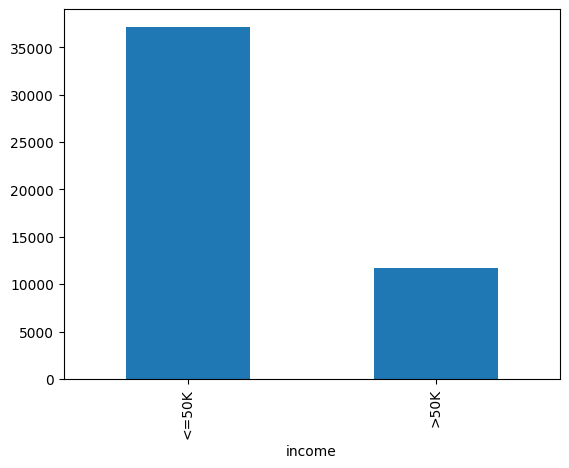

In [ ]:
print(df['income'].value_counts(normalize=True))
df['income'].value_counts().plot(kind='bar')

В дальнейшем будем учитывать, что в датасете гораздо больше людей с доходом `<=50K ` (то есть классы несбалансированы).


Теперь посмотрим на пропуски.

In [ ]:
df = df.replace('?', pd.NA)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
df = df.fillna('Unknown')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


In [ ]:
# Есть ли опечатки в названиях категорий? Редкие категории?
for col in cat_cols:
    print('\n', col)
    display(df[col].value_counts().head(10))


 workclass


,count
workclass,
Private,33906
Self-emp-not-inc,3862
Local-gov,3136
Unknown,2799
State-gov,1981
Self-emp-inc,1695
Federal-gov,1432
Without-pay,21
Never-worked,10



 education


,count
education,
HS-grad,15784
Some-college,10878
Bachelors,8025
Masters,2657
Assoc-voc,2061
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,955



 marital_status


...

,count
race,
White,41762
Black,4685
Asian-Pac-Islander,1519
Amer-Indian-Eskimo,470
Other,406



 sex


,count
sex,
Male,32650
Female,16192



 native_country


,count
native_country,
United-States,43832
Mexico,951
Unknown,857
Philippines,295
Germany,206
Puerto-Rico,184
Canada,182
El-Salvador,155
India,151


Деревья решений плохо справляются с категориальными признаками с большим количеством меток.

In [ ]:
cat_cols = df.select_dtypes('object').columns.drop('income')
for col in cat_cols:
    vc = df[col].value_counts()
    rare = vc[vc < 0.01 * len(df)].index   # Порог = 1% от всей выборки
    df[col] = df[col].replace(rare, 'other')
    df[col] = df[col].str.strip()          # Ещё раз обрежем пробелы

In [ ]:
cat_cols = df.select_dtypes('object').columns.drop('income')
for col in cat_cols:
    print('\n', col)
    display(df[col].value_counts().head(10))


 workclass


,count
workclass,
Private,33906
Self-emp-not-inc,3862
Local-gov,3136
Unknown,2799
State-gov,1981
Self-emp-inc,1695
Federal-gov,1432
other,31



 education


,count
education,
HS-grad,15784
Some-college,10878
Bachelors,8025
Masters,2657
Assoc-voc,2061
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,955



 marital_status


...

,count
race,
White,41762
Black,4685
Asian-Pac-Islander,1519
other,876



 sex


,count
sex,
Male,32650
Female,16192



 native_country


,count
native_country,
United-States,43832
other,3202
Mexico,951
Unknown,857


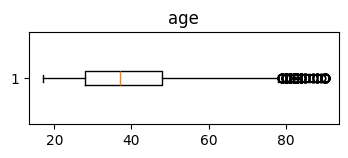

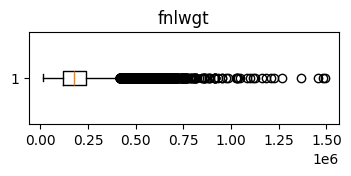

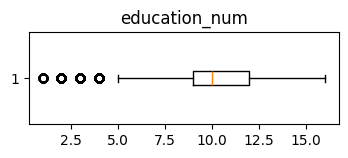

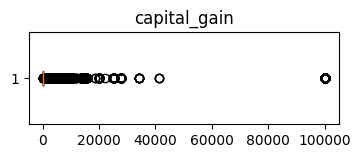

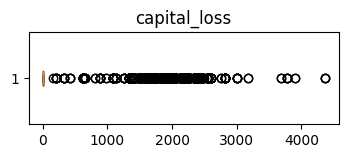

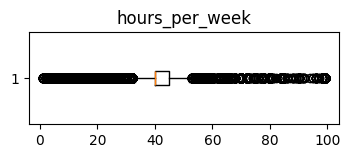

In [ ]:
# Распределения числовых переменных
for col in num_cols:
    plt.figure(figsize=(4,1.2))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(col); plt.show()

In [ ]:
(df['capital_gain'] > 0).astype(int).value_counts()

,count
capital_gain,
0,44807
1,4035


In [ ]:
# age: разбиение на отрезки
df['age_bin'] = pd.cut(df['age'], bins=[16,25,35,45,55,65,100],
                       labels=['17-25','26-35','36-45','46-55','56-65','66+'])

# fnlwgt убираем, бесполезная фича
df = df.drop('fnlwgt', axis=1)

# capital_gain/capital_loss → флаги
df['gain_flag'] = (df['capital_gain'] > 0).astype(int)
df['loss_flag'] = (df['capital_loss'] > 0).astype(int)

# hours_per_week: разбиение на отрезки
df['hours_bin'] = pd.cut(df['hours_per_week'],
                         bins=[0,40,55,168],
                         labels=['<=40','41-55','56+'])

In [ ]:
# Проверим результат
df[['age','age_bin', 'capital_gain','gain_flag','capital_loss','loss_flag',
          'hours_per_week','hours_bin']].head()

,age,age_bin,capital_gain,gain_flag,capital_loss,loss_flag,hours_per_week,hours_bin
0,39,36-45,2174,1,0,0,40,<=40
1,50,46-55,0,0,0,0,13,<=40
2,38,36-45,0,0,0,0,40,<=40
3,53,46-55,0,0,0,0,40,<=40
4,28,26-35,0,0,0,0,40,<=40


Теперь у нас много категориальных переменных. Превратим их в dummy-переменные.

In [ ]:
df = pd.get_dummies(df, drop_first=True, dtype=int)
df.head()

,age,education_num,capital_gain,capital_loss,hours_per_week,gain_flag,loss_flag,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native_country_Unknown,native_country_other,income_>50K,age_bin_26-35,age_bin_36-45,age_bin_46-55,age_bin_56-65,age_bin_66+,hours_bin_41-55,hours_bin_56+
0,39,13,2174,0,40,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,50,13,0,0,13,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,38,9,0,0,40,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
3,53,7,0,0,40,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,28,13,0,0,40,0,0,0,1,0,...,0,1,0,1,0,0,0,0,0,0


In [ ]:
# Все ли признаки числовые теперь?
df.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Columns: 67 entries, age to hours_bin_56+
dtypes: int64(67)
memory usage: 25.0 MB


In [ ]:
X = df.drop('income_>50K', axis=1)
y = df['income_>50K']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y) # stratify нужен, так как целевая несбалансирована

### Задача 4. `sklearn`: ограниченное дерево [2 балла]

Начнём сразу с ограниченного дерева, так как неограниченные деревья часто приводят к переобучению. На этот раз применим post-pruning.





#### Задача 4.1 [**1 балл**]

- Построй полное дерево классификации, используя критерии Джини и энтропии. Помни: целевая переменная несбалансирована, учти это при обучении дерева. Присмотрись к параметру `class_weight` в `DecisionTreeClassifier`.

- Добавь post-pruning «стрижку» деревьев через гиперпараметр $\alpha$. Так как полное дерево получается огромным, количество $\alpha$ тоже будет большим, и подбор оптимального значения $\alpha$ займёт много времени. Вместо этого равномерно просемплируй 300 значений $\alpha$ из общего пула $\alpha$ (можешь использовать `np.linspace`).

- Оцени для этих значений $\alpha$ качество модели только на тестовом датасете. Классы целевого признака несбалансированы, потому метрика `accuracy` ни о чём полезном нам не скажет.

- Вместо точности посчитай метрики ROC-AUC, которые гораздо устойчивее к дисбалансу в $Y$.

- В итоге у тебя должны получиться списки `test_gini`, `test_entropy` из значений ROC-AUC для каждого из трёхсот значений $\alpha$ отдельно для критериев Джини и энтропии. При оценке качества не забудь про `class_weight` в `DecisionTreeClassifier`.

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html

https://numpy.org/doc/2.1/reference/generated/numpy.linspace.html

In [ ]:
from sklearn.metrics import roc_auc_score
# Напиши код здесь
path = DecisionTreeClassifier(random_state=42)
path = path.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas
if len(ccp_alphas) > 1:
    alphas = np.linspace(ccp_alphas[0], ccp_alphas[-2], 300)
else:
    alphas = [0.0]

test_gini = []
test_entropy = []

for alpha in alphas:
    clf_gini = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha, class_weight='balanced')
    clf_gini.fit(X_train, y_train)
    prob_gini = clf_gini.predict_proba(X_test)[:, 1]
    test_gini.append(roc_auc_score(y_test, prob_gini))

    clf_entropy = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha, class_weight='balanced', criterion='entropy')
    clf_entropy.fit(X_train, y_train)
    prob_entropy = clf_entropy.predict_proba(X_test)[:, 1]
    test_entropy.append(roc_auc_score(y_test, prob_entropy))

#### Задача 4.2 [1 балл]

- Используя массивы из предыдущего задания, нарисуй, как тестовая точность зависит от ограничивающего гиперпараметра $\alpha$ в случаях Джини и энтропии.

- Используй все значения $\alpha$, кроме двух самых больших (при них ROC-AUC резко падают из-за недообучения, и картинка портится). Используй `plt.plot`.

- Для двух оптимальных значений $\alpha$ (для Джини/энтропии) обучи деревья классификации и для них построй confusion-matrix
 (`sklearn.metrics.ConfusionMatrixDisplay`).

- Дополнительно можешь проанализировать, сильно ли две confusion-матрицы отличаются друг от друга.

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

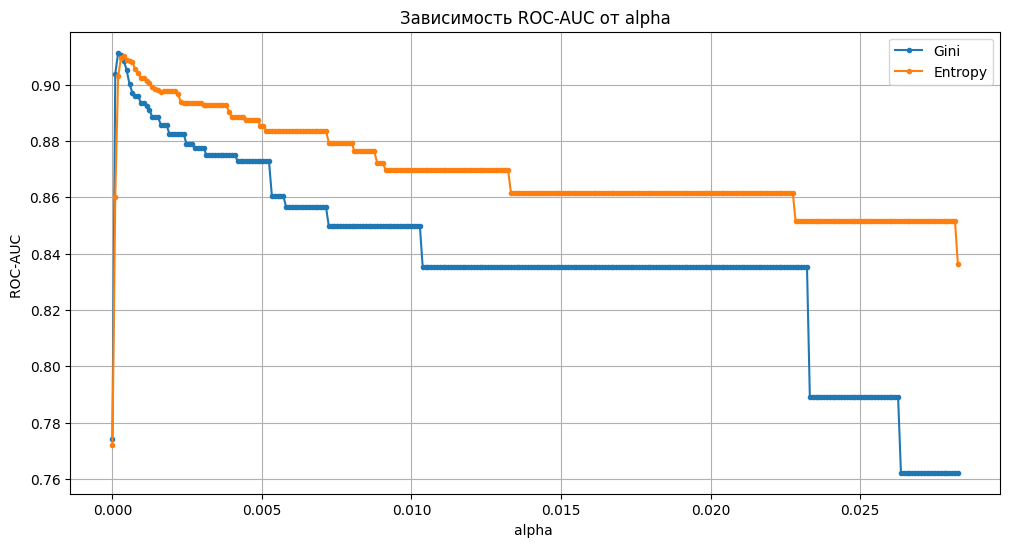

Лучший alpha для Gini: 0.00019037123074436271, AUC: 0.9113
Лучший alpha для Entropy: 0.00038074246148872543, AUC: 0.9101


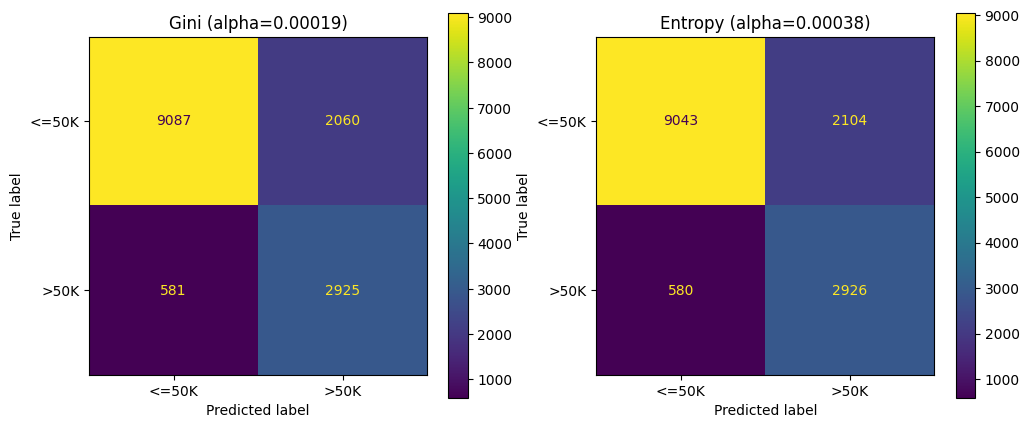

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Напиши код здесь
valid_indices = slice(None, -2)
plt.figure(figsize=(12, 6))
plt.plot(alphas[valid_indices], np.array(test_gini)[valid_indices], label='Gini', marker='.')
plt.plot(alphas[valid_indices], np.array(test_entropy)[valid_indices], label='Entropy', marker='.')
plt.xlabel('alpha ')
plt.ylabel('ROC-AUC ')
plt.title('Зависимость ROC-AUC от alpha')
plt.legend()
plt.grid(True)
plt.show()

best_alpha_gini = alphas[np.argmax(test_gini)]
best_alpha_entropy = alphas[np.argmax(test_entropy)]

print(f"Лучший alpha для Gini: {best_alpha_gini}, AUC: {max(test_gini):.4f}")
print(f"Лучший alpha для Entropy: {best_alpha_entropy}, AUC: {max(test_entropy):.4f}")

clf_best_gini = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha_gini, class_weight='balanced')
clf_best_gini.fit(X_train, y_train)
y_pred_gini = clf_best_gini.predict(X_test)

clf_best_entropy = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha_entropy, class_weight='balanced', criterion='entropy')
clf_best_entropy.fit(X_train, y_train)
y_pred_entropy = clf_best_entropy.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gini, ax=axes[0], display_labels=['<=50K', '>50K'])
axes[0].set_title(f'Gini (alpha={best_alpha_gini:.5f})')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_entropy, ax=axes[1], display_labels=['<=50K', '>50K'])
axes[1].set_title(f'Entropy (alpha={best_alpha_entropy:.5f})')
plt.show()

###Задача 5. Расширение функционала `MyDecisionTreeClassifier` [3 балла]  

Ниже приведён класс дерева классификации из семинара 2. Он немного отличается по внешнему виду от класса в секции регрессий, но по функционалу во многом похож.

Этот класс неполный, и надо его улучшить под наши задачи. Мы уже усилили его в коде ниже (смотри строки с комментарием NEW), в том числе добавив возможность обучения по критерию энтропии и стохастическую настройку `random state`.


In [ ]:
from typing import Optional, Union, Dict

class _Node:
    """Вершина дерева (и внутренний узел, и лист)."""
    def __init__(self, feat=None, thr=None, left=None, right=None,
                 proba=None, label=None):
        self.feat = feat      # Индекс признака для сплита
        self.thr = thr        # Порог сплита
        self.left = left      # Левая ветка
        self.right = right    # Правая ветка
        self.proba = proba    # Вероятности классов (только в листе)
        self.label = label    # Метка класса (только в листе)

    def is_leaf(self):
        """Возвращает True, если вершина является листом."""
        return self.label is not None


class MyDecisionTreeClassifier:
    """
    Мини-реализация дерева классификации (критерий Gini,
    бинарные сплиты по порогу).
    """

    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        criterion: str = "gini",                     # #### NEW
        class_weight: Union[str, Dict[int, float], None] = None,  # #### NEW — твоё следующее задание
        ccp_alpha: float = 0.0,                      # #### NEW — твоё следующее задание
        random_state: Optional[int] = None           # #### NEW
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion                   # #### NEW
        self.class_weight = class_weight             # #### NEW — твоё следующее задание
        self.ccp_alpha = float(ccp_alpha)            # #### NEW — твоё следующее задание
        if random_state is not None:                 # #### NEW
            np.random.seed(random_state)             # #### NEW

    # ---------- Методы, реализованные вручную ----------
    def _make_leaf(self, y_subset: np.ndarray) -> _Node:
        """
        Превращает подмножество объектов в лист и
        возвращает объект `_Node` с полями `proba`, `label`.
        """
        counts = np.bincount(y_subset)
        proba  = counts / counts.sum()
        return _Node(proba=proba, label=int(proba.argmax()))

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        """
        Спускает один объект по дереву до листа
        и возвращает предсказанный класс.
        """
        while not node.is_leaf():
            node = node.left if x_row[node.feat] <= node.thr else node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        """
        Возвращает вектор прогнозов для всей матрицы `X`.

        Обрати внимание: мы сразу преобразуем X в numpy-массив,
        чтобы не индексировать строки как строки или pandas-объекты.
        """
        X_arr = np.asarray(X, dtype=float)
        return np.array([self._predict_one(row, self.root_) for row in X_arr])

    # ----------------------------------------------------

    # ---------- Готовые вспомогательные методы ----------
    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        return 1.0 - (p ** 2).sum()

    @staticmethod
    def _entropy(counts: np.ndarray) -> float:             # NEW
        p = counts / counts.sum()
        p = p[p > 0]
        return -(p * np.log2(p)).sum()

    def _impurity(self, counts: np.ndarray) -> float:      # NEW
        return self._gini(counts) if self.criterion == "gini" else self._entropy(counts)

    def _best_split(self, X: np.ndarray, y: np.ndarray):
        """
        Перебирает все признаки и ищет порог,
        дающий максимальный прирост информации.
        Возвращает (feat, thr). Если сплита нет — (None, None).
        """
        best_gain, best_feat, best_thr = -np.inf, None, None
        parent_imp = self._gini(np.bincount(y))
        for feat in range(X.shape[1]):
            xs = X[:, feat]
            order = np.argsort(xs)
            xs_sort, y_sort = xs[order], y[order]
            right = np.bincount(y_sort).astype(float)
            left  = np.zeros_like(right)
            for i in range(1, len(y_sort)):
                cls = y_sort[i - 1]
                left[cls]  += 1
                right[cls] -= 1
                if xs_sort[i] == xs_sort[i - 1]:
                    continue
                if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                    continue
                wL = i / len(y_sort)
                wR = 1 - wL
                gain = parent_imp - (wL * self._gini(left) + wR * self._gini(right))
                if gain > best_gain:
                    best_gain, best_feat = gain, feat
                    best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
        return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, depth: int = 0) -> _Node:
        """
        Рекурсивно строит дерево, возвращая корневой узел `_Node`.
        """
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return self._make_leaf(y)

        feat, thr = self._best_split(X, y)
        if feat is None:
            return self._make_leaf(y)

        mask = X[:, feat] <= thr
        left  = self._grow(X[mask],  y[mask],  depth + 1)
        right = self._grow(X[~mask], y[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def fit(self, X, y):
        """
        Строит дерево по обучающим данным.
        Если `y` содержит строковые метки, сначала преобразует их в целые.
        """
        # Приводим X, y к numpy-массиву целых
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)

        if y_arr.dtype.kind in {'U', 'S', 'O'}:
            _, y_int = np.unique(y_arr, return_inverse=True)
            y_arr = y_int
        else:
            y_arr = y_arr.astype(int).ravel()

        self.root_ = self._grow(X_arr, y_arr)
        return self

Давай дополним этот класс.





#### Задача 5.1. [1 балл]

- Внедри гиперпараметр `ccp_alpha` как pre-pruning-регулятор. Гиперпараметр `ccp_alpha` должен остановить рост дерева, когда функционал качества (с учётом штрафа `ccp_alpha`) уже не может быть улучшен никаким сплитом. То есть когда взвешенная мера неопределённости двух дочерних узлов больше, чем неопределённость в родительском узле.


- Присмотрись к методу `_best_split` нашего класса. В него нужно внести минимальные изменения, которые учтут влияние гиперпараметра `self.ccp_alpha` и остановят рост дерева, если дальнейший рост качества невозможен.

>**Подсказка**. Решение состоит из 2–3 строчек. Написать решение можешь в виде функции, которая выглядит как метод класса. При решении можешь прямо скопировать метод выше.

In [ ]:
# Напиши код здесь
def _best_split(self, X: np.ndarray, y: np.ndarray):
    """
    Перебирает все признаки и ищет порог,
    дающий максимальный прирост информации.
    Возвращает (feat, thr). Если сплита нет — (None, None).
    """
    best_gain, best_feat, best_thr = -np.inf, None, None
    parent_imp = self._gini(np.bincount(y))
    for feat in range(X.shape[1]):
        xs = X[:, feat]
        order = np.argsort(xs)
        xs_sort, y_sort = xs[order], y[order]
        right = np.bincount(y_sort).astype(float)
        left  = np.zeros_like(right)
        for i in range(1, len(y_sort)):
            cls = y_sort[i - 1]
            left[cls]  += 1
            right[cls] -= 1
            if xs_sort[i] == xs_sort[i - 1]:
                continue
            if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                continue
            wL = i / len(y_sort)
            wR = 1 - wL
            gain = parent_imp - (wL * self._gini(left) + wR * self._gini(right))
            if gain < self.ccp_alpha:
                continue
            if gain > best_gain:
                best_gain, best_feat = gain, feat
                best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
    return best_feat, best_thr

#### Задача 5.2. [1 балл]

Теперь попробуем внедрить гиперпараметр `class_weight`, который будет учитывать веса наблюдений при обучении дерева. Это непростая задача, так как `class_weight` затрагивает работу многих методов класса. Все методы исправлять не нужно.

Твоя задача — включить `class_weight` только в основной метод `fit()`, от которого эти веса «пойдут дальше» по другим методам.

После этого упражнения протестируй, насколько правильно дописан метод `fit()`.

Полезные ссылки:

https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html,

https://numpy.org/doc/2.2/reference/generated/numpy.ones.html.

In [ ]:
def fit(self, X, y):
    X_arr = np.asarray(X, dtype=float)
    y_arr = np.asarray(y)

    if y_arr.dtype.kind in {'U', 'S', 'O'}:
        _, y_int = np.unique(y_arr, return_inverse=True)
        y_arr = y_int
    else:
        y_arr = y_arr.astype(int).ravel()

    # Напиши код здесь
    # ---- class_weight-обработка ----   #### NEW
    self.n_classes = len(np.bincount(y_arr))
    if self.class_weight == 'balanced':    # Смотри полезные ссылки выше
        counts = np.bincount(y_arr)
        n = counts.sum()
        w_vec = n / (len(counts) * counts)

    elif isinstance(self.class_weight, dict):
        max_label = y_arr.max()
        w = np.ones(max_label + 1)
        for k, v in self.class_weight.items():
            w[int(k)] = v
        w_vec = w

    else:
        # Тут равномерное распределение (смотри полезные ссылки выше)
        w_vec = np.ones(self.n_classes)

    # --------------------------------------

    self.root_ = self._grow(X_arr, y_arr)
    return self

#### Задача 5.3. [Обязательная]

Наконец, построим итоговый класс. Чтобы работать с весами меток целевой переменной, этот класс видоизменён. Всё, что тебе нужно сейчас сделать, — скопировать сюда свои решения.

>**Важно!** Без выполнения этого задания баллы за задачу 5 не начисляются.

In [ ]:
from typing import Optional, Union, Dict


class _Node:
    def __init__(self, feat=None, thr=None, left=None, right=None, proba=None, label=None):
        self.feat = feat
        self.thr = thr
        self.left = left
        self.right = right
        self.proba = proba
        self.label = label

    def is_leaf(self):
        return self.label is not None


class MyDecisionTreeClassifier:
    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        criterion: str = "gini",
        class_weight: Union[str, Dict[int, float], None] = None,
        ccp_alpha: float = 0.0,
        random_state: Optional[int] = None
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.class_weight = class_weight
        self.ccp_alpha = float(ccp_alpha)
        if random_state is not None:
            np.random.seed(random_state)

    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        return 1.0 - (p ** 2).sum()

    @staticmethod
    def _entropy(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        p = p[p > 0]
        return -(p * np.log2(p)).sum()

    def _impurity(self, counts: np.ndarray) -> float:
        return self._gini(counts) if self.criterion == "gini" else self._entropy(counts)

    def _make_leaf(self, y_subset: np.ndarray, w_subset: np.ndarray) -> _Node:
        counts = np.bincount(y_subset, weights=w_subset, minlength=self.n_classes_)
        proba = counts / counts.sum()
        return _Node(proba=proba, label=int(proba.argmax()))

    def _best_split(self, X: np.ndarray, y: np.ndarray, w: np.ndarray):

        # Напиши свой метод здесь
      """
      Перебирает все признаки и ищет порог,
      дающий максимальный прирост информации.
      Возвращает (feat, thr). Если сплита нет — (None, None).
      """
      best_gain, best_feat, best_thr = -np.inf, None, None
      parent_imp = self._gini(np.bincount(y))
      for feat in range(X.shape[1]):
          xs = X[:, feat]
          order = np.argsort(xs)
          xs_sort, y_sort = xs[order], y[order]
          right = np.bincount(y_sort).astype(float)
          left  = np.zeros_like(right)
          for i in range(1, len(y_sort)):
              cls = y_sort[i - 1]
              left[cls]  += 1
              right[cls] -= 1
              if xs_sort[i] == xs_sort[i - 1]:
                  continue
              if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                  continue
              wL = i / len(y_sort)
              wR = 1 - wL
              gain = parent_imp - (wL * self._gini(left) + wR * self._gini(right))
              if gain < self.ccp_alpha:
                  continue
              if gain > best_gain:
                  best_gain, best_feat = gain, feat
                  best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
      return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, w: np.ndarray, depth: int = 0) -> _Node:
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or w.sum() < self.min_samples_split:
            return self._make_leaf(y, w)
        feat, thr = self._best_split(X, y, w)
        if feat is None:
            return self._make_leaf(y, w)
        mask = X[:, feat] <= thr
        left = self._grow(X[mask], y[mask], w[mask], depth + 1)
        right = self._grow(X[~mask], y[~mask], w[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        while not node.is_leaf():
            node = node.left if x_row[node.feat] <= node.thr else node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        return np.array([self._predict_one(row, self.root_) for row in X_arr])

    def predict_proba(self, X):
        X_arr = np.asarray(X, dtype=float)
        probs = []
        for row in X_arr:
            node = self.root_
            while not node.is_leaf():
                node = node.left if row[node.feat] <= node.thr else node.right
            probs.append(node.proba)
        return np.vstack(probs)

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)
        if y_arr.dtype.kind in {'U', 'S', 'O'}:
            _, y_int = np.unique(y_arr, return_inverse=True)
            y_arr = y_int
        else:
            y_arr = y_arr.astype(int).ravel()

        self.n_classes_ = len(np.bincount(y_arr))


        # Напиши свой блок кода здесь
        if self.class_weight == 'balanced':    # Смотри полезные ссылки выше
            counts = np.bincount(y_arr)
            n = counts.sum()
            w_vec = n / (len(counts) * counts)

        elif isinstance(self.class_weight, dict):
            max_label = y_arr.max()
            w = np.ones(max_label + 1)
            for k, v in self.class_weight.items():
                w[int(k)] = v
            w_vec = w

        else:
            # Тут равномерное распределение (смотри полезные ссылки выше)
            w_vec = np.ones(self.n_classes)

        sample_w = w_vec[y_arr]
        self.root_ = self._grow(X_arr, y_arr, sample_w)
        return self

#### Задача 5.4 [1 балл]

- Обучи дерево решений, используя наш класс. Примени критерий Джини.

- Добейся ROC-AUC в 0,79 на нашем классе. Помни, что `ccp_alpha` у нас регулятор pre-pruning, а не post-pruning. Это значит, что на некоторых данных применение такого гиперпараметра может ухудшать качество.

- Сравни эффективность нашего класса с классом из библиотеки scikit-learn (устно, для себя).

In [ ]:
# Обучим дерево на данных Adult, используя наш класс

custom_tree=MyDecisionTreeClassifier(max_depth=10,
                                     min_samples_leaf=50,
                                     class_weight='balanced',
                                     criterion='gini',
                                     ccp_alpha=0.001,
                                     random_state=42)
custom_tree.fit(X_train,y_train)
y_pred_prob_custom=custom_tree.predict_proba(X_test)[:,1]
auc_custom=roc_auc_score(y_test,y_pred_prob_custom)


sklearn_tree = DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight='balanced', random_state=42)
sklearn_tree.fit(X_train, y_train)

print("Custom tree ROC-AUC:",auc_custom)
print("Sklearn tree ROC-AUC:", roc_auc_score(y_test, sklearn_tree.predict_proba(X_test)[:, 1]))

Custom tree ROC-AUC: 0.9016394942225943
Sklearn tree ROC-AUC: 0.9055477234658694


### Теоретические вопросы [1 балл]

1. Как влияют гиперпараметры `max_depth, min_samples_split, min_samples_leaf` на bias-variance дерева решений? [0.5 балла]

2. Почему один и тот же датасет может давать такие разные деревья при малых изменениях данных? [0.5 балла]


1.Ограничение max_depth уменьшает сложность модели, предотвращая переобучение. Но можно перестараться и модель будет слишеом простой.

min_samples_split определяет пророг разделения обьектов. Увеличивание упрощает модель, предотвращая переобучение. Но можно перестараться и модель будет слишеом простой.

min_samples_leaf определяет минимальное количество объектов в листе. Большие значения сглаживают предсказания.


2.Деревья решений обладают высокой дисперсией. Небольшое изменение в обучающей выборке может изменить лучший признак для разбиения в корневом узле. Поскольку все последующие разбиения зависят от предыдущих, это изменение распространяется по всему дереву, приводя к разной структуре. Это называется высокой чувствительностью к данным.

----------------------------------------------------------------